In [1]:
# converting J2014 to binary 

In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import os
import h5py

import matplotlib as mpl
from matplotlib import colormaps

In [5]:

CLAY_FILE = "J2014-C2-SMA_CLAY_minfrac_0.083deg.nc"
SILT_FILE = "J2014-C2-SMA_SILT_minfrac_0.083deg.nc"

In [6]:
OUT_ROOT = "J2014_GEOGRID"

# WPS binary settings
PRECISION = 0.00001
WORDSIZE = 4
MISSING_VALUE = 0

In [ ]:

CLAY_VARS = ["ILLITE", "SMECTITE", "KAOLINITE", "CHLORITE","VERMICULITE", "FELDSPARS", "QUARTZ", "CALCITE","HEMATITE", "GOETHITE", "GYPSUM"]

SILT_VARS = [ "CALCITE", "GYPSUM", "MICA", "CHLORITE","FELDSPARS", "QUARTZ", "GOETHITE"]

In [ ]:

def write_index(folder, dx, dy, known_lat, known_lon, tile_x, tile_y, description):
    index_text = f"""type=continuous
signed=yes
projection=regular_ll
dx={dx}
dy={dy}
known_x=1.0
known_y=1.0
known_lat={known_lat}
known_lon={known_lon}
wordsize={WORDSIZE}
tile_x={tile_x}
tile_y={tile_y}
tile_z=1
scale_factor={PRECISION}
#missing_value={MISSING_VALUE}
units="fraction"
description="{description}"
"""
    with open(os.path.join(folder, "index"), "w") as f:
        f.write(index_text)


In [ ]:


def convert_to_geogrid(ncfile, variables, prefix):
    ds = xr.open_dataset(ncfile)

    lat = ds["latitude"].values
    lon = ds["longitude"].values

    dy = abs(float(lat[1] - lat[0]))
    dx = abs(float(lon[1] - lon[0]))

    tile_y = len(lat)
    tile_x = len(lon)

    known_lat = float(np.min(lat))
    known_lon = float(lon[0])

    binary_name = f"00001-{tile_x:05d}.00001-{tile_y:05d}"

    for var in variables:
        print(f"Converting {prefix}_{var}")

        data = ds[var].values.astype(np.float64)

        # WPS wants rows from south to north
        if lat[0] > lat[-1]:
            data = np.flipud(data)

        # Clean missing/invalid values
        data = np.where(np.isfinite(data), data, MISSING_VALUE)

        # Scale real fraction to integer
        scaled = np.rint(data / PRECISION).astype(np.int64)

        # Convert to big-endian 4-byte integer
        scaled = scaled.astype(">i4")

        folder_name = f"{prefix.lower()}_{var.lower()}"
        folder = os.path.join(OUT_ROOT, folder_name)
        os.makedirs(folder, exist_ok=True)

        # Write binary file: no header
        scaled.tofile(os.path.join(folder, binary_name))

        # Write index file
        write_index(
            folder=folder,
            dx=dx,
            dy=dy,
            known_lat=known_lat,
            known_lon=known_lon,
            tile_x=tile_x,
            tile_y=tile_y,
            description=f"{prefix} {var} mineral fraction"
        )




In [ ]:


convert_to_geogrid(CLAY_FILE, CLAY_VARS, "J2014_CLAY")
convert_to_geogrid(SILT_FILE, SILT_VARS, "J2014_SILT")


Converting J2014_CLAY_ILLITE
Converting J2014_CLAY_SMECTITE
Converting J2014_CLAY_KAOLINITE
Converting J2014_CLAY_CHLORITE
Converting J2014_CLAY_VERMICULITE
Converting J2014_CLAY_FELDSPARS
Converting J2014_CLAY_QUARTZ
Converting J2014_CLAY_CALCITE
Converting J2014_CLAY_HEMATITE
Converting J2014_CLAY_GOETHITE
Converting J2014_CLAY_GYPSUM
Converting J2014_SILT_CALCITE
Converting J2014_SILT_GYPSUM
Converting J2014_SILT_MICA
Converting J2014_SILT_CHLORITE
Converting J2014_SILT_FELDSPARS
Converting J2014_SILT_QUARTZ
Converting J2014_SILT_GOETHITE
Done. Output written to: J2014_GEOGRID


In [ ]:
# check the conversion 

In [11]:
import xarray as xr
import numpy as np

ncfile = "J2014-C2-SMA_CLAY_minfrac_0.083deg.nc"
binfile = "J2014_GEOGRID/j2014_clay_calcite/00001-04322.00001-02160"

varname = "CALCITE"
precision = 0.00001
nx = 4322
ny = 2160

# Original data
ds = xr.open_dataset(ncfile)
orig = ds[varname].values.astype(float)

# Flip original because binary was written south-to-north
lat = ds["latitude"].values
if lat[0] > lat[-1]:
    orig = np.flipud(orig)

# Read binary
raw = np.fromfile(binfile, dtype=">i4").reshape(ny, nx)

# Convert back to real values
back = raw * precision

# Difference
diff = back - orig

print("Original min/max:", np.nanmin(orig), np.nanmax(orig))
print("Binary back min/max:", np.nanmin(back), np.nanmax(back))
print("Difference min/max:", np.nanmin(diff), np.nanmax(diff))
print("Mean absolute difference:", np.nanmean(np.abs(diff)))

Original min/max: 0.0 0.9330905780609923
Binary back min/max: 0.0 0.9330900000000001
Difference min/max: -4.850130046196721e-06 4.943097476496801e-06
Mean absolute difference: 1.4067007812294767e-06


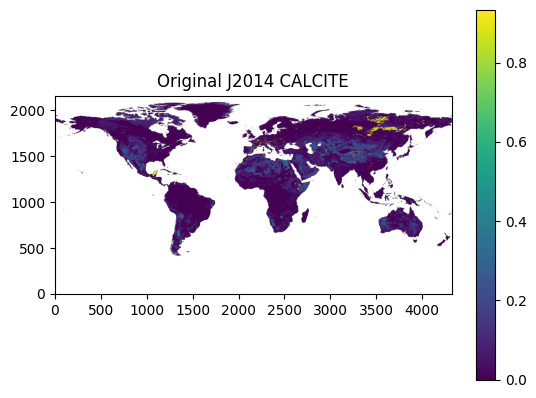

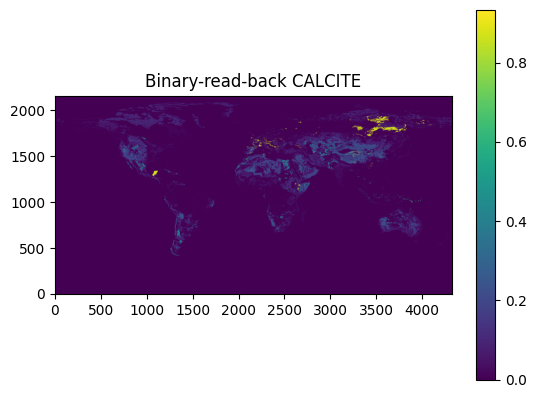

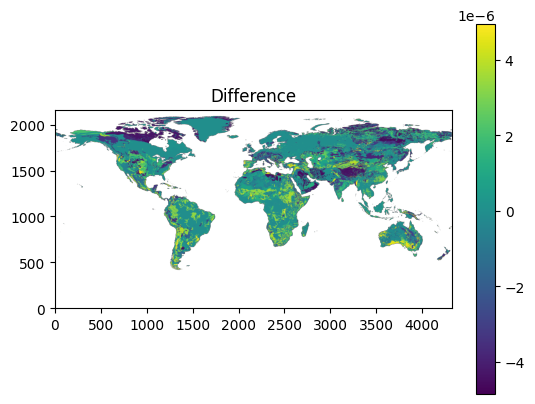

In [12]:
import matplotlib.pyplot as plt

plt.figure()
plt.imshow(orig, origin="lower")
plt.title("Original J2014 CALCITE")
plt.colorbar()
plt.show()

plt.figure()
plt.imshow(back, origin="lower")
plt.title("Binary-read-back CALCITE")
plt.colorbar()
plt.show()

plt.figure()
plt.imshow(back - orig, origin="lower")
plt.title("Difference")
plt.colorbar()
plt.show()